# Session 2: Conditional Probability and Independence

*ECE 225A, Module 01 (Probability Review), slides 13-33*

Session 1 computed the probability of one event at a time. This session handles several events at once. It starts with set operations that combine events, then asks how learning that one event happened changes the probability of another (**conditional probability**), and singles out the case where it changes nothing (**independence**). Conditioning then gives the **product and chain rules**, which break a complicated event into a sequence of simple steps. The session ends with the birthday paradox, where all of these tools work together.

## Learning objectives

After this session you should be able to:

1. Compute probabilities of complements, unions, intersections, and differences, using inclusion-exclusion for unions.
2. Read $P(F \mid E)$ as a long-run fraction and as a probability on the restricted sample space $E$, and compute it as $P(E \cap F)/P(E)$.
3. Classify two events as positively correlated, negatively correlated, or independent.
4. State the informal and the formal definitions of independence, and explain why the formal one is preferred.
5. Tell pairwise independence of three events from mutual independence, with an example where they differ.
6. Compute the probability of an intersection with the product rule and the chain rule, especially for draws without replacement.
7. Derive the exact birthday probability, its exponential approximation, and the $\sqrt{365}$ heuristic.

## Prerequisites

- Sample spaces, events, and equiprobable spaces with $P(E) = |E|/|\Omega|$ (Session 1).
- Counting ordered and unordered selections, $\binom{n}{k}$ (Session 1).
- $e^x$, $\ln x$, and the sum $1 + 2 + \cdots + m = m(m+1)/2$.

In [1]:
from fractions import Fraction
from math import comb, perm, prod, exp, log, sqrt
from itertools import product, combinations, permutations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, p):
    # Print a probability as an exact fraction and as a decimal.
    print(f"{label}: {p} = {float(p):.6f}")

## 1. Combining events: set operations (slides 13-14)

**Intuition.** Real questions rarely involve a single event. "Does the student own an iPhone *or* an Android phone?" "Is the card a heart *and* a face card?" "Did the part pass test A *but not* test B?" Each question builds a new event out of old ones with a set operation, and each set operation has a rule for its probability.

**Formal statements.** For events $A, B \subseteq \Omega$:

| Operation | Event | Happens when | Probability |
|---|---|---|---|
| Complement | $A^c = \Omega - A$ | $A$ does not happen | $P(A^c) = 1 - P(A)$ |
| Intersection | $A \cap B$ | both happen | no general formula yet (product rule, Section 12) |
| Union | $A \cup B$ | at least one happens | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ |
| Difference | $A - B = A \cap B^c$ | $A$ happens but $B$ does not | $P(A - B) = P(A) - P(A \cap B)$ |

**Why they hold.** Every rule comes from additivity: the probability of a union of *disjoint* events is the sum of their probabilities.

- $A$ and $A^c$ are disjoint and together make up $\Omega$, so $P(A) + P(A^c) = 1$.
- $A$ splits into the disjoint pieces $A - B$ and $A \cap B$, so $P(A) = P(A - B) + P(A \cap B)$. That is the difference rule.
- $A \cup B$ splits into the disjoint pieces $A - B$, $A \cap B$, and $B - A$, so
$$P(A \cup B) = \big[P(A) - P(A \cap B)\big] + P(A \cap B) + \big[P(B) - P(A \cap B)\big] = P(A) + P(B) - P(A \cap B).$$
In words: $P(A) + P(B)$ counts the overlap twice, so subtract it once. This is **inclusion-exclusion**.

**Python check.** The slide has no numbers, so test the rules on one roll of a fair die with $A = \lbrace 2, 4, 6 \rbrace$ (even) and $B = \lbrace 4, 5, 6 \rbrace$ (at least 4). Python sets have the same operations: `|` is union, `&` is intersection, `-` is difference.

In [2]:
omega = set(range(1, 7))   # one roll of a fair die


def P_die(event):
    return Fraction(len(event), len(omega))


A, B = {2, 4, 6}, {4, 5, 6}   # even, at least 4
show("P(A^c)              ", P_die(omega - A))
show("1 - P(A)            ", 1 - P_die(A))
show("P(A u B)            ", P_die(A | B))
show("P(A) + P(B) - P(AnB)", P_die(A) + P_die(B) - P_die(A & B))
show("P(A - B)            ", P_die(A - B))
show("P(A) - P(AnB)       ", P_die(A) - P_die(A & B))

P(A^c)              : 1/2 = 0.500000
1 - P(A)            : 1/2 = 0.500000
P(A u B)            : 2/3 = 0.666667
P(A) + P(B) - P(AnB): 2/3 = 0.666667
P(A - B)            : 1/6 = 0.166667
P(A) - P(AnB)       : 1/6 = 0.166667


## 2. Example: phone owners (slide 15)

**Setup.** A class has 100 students. 50 own an iPhone, 30 own an Android phone, and 10 own both. Pick a student at random. What is the probability that the student owns neither kind?

Let $I$ = "owns an iPhone" and $A$ = "owns an Android". Then $P(I) = 0.5$, $P(A) = 0.3$, and $P(I \cap A) = 0.1$.

**Step by step.**

1. "Neither" is the complement of "at least one": $\text{neither} = (I \cup A)^c$.
2. Inclusion-exclusion: $P(I \cup A) = 0.5 + 0.3 - 0.1 = 0.7$. The 10 students who own both appear in the 50 *and* in the 30, so $50 + 30$ counts them twice.
3. Complement: $P(\text{neither}) = 1 - 0.7 = 0.3$.

The Venn diagram cuts the class into four disjoint regions: iPhone only ($50 - 10 = 40$), both (10), Android only ($30 - 10 = 20$), and neither (30). The four counts add to 100. A common slip is $1 - 0.5 - 0.3 = 0.2$, which removes the 10 double owners twice.

**Python check.** Build the class as 100 records and count directly.

In [3]:
# One record per student: (owns iPhone, owns Android)
students = [(True, True)] * 10 + [(True, False)] * 40 + [(False, True)] * 20 + [(False, False)] * 30


def P_class(event):
    return Fraction(sum(event(s) for s in students), len(students))


iphone = lambda s: s[0]
android = lambda s: s[1]
show("P(I u A), direct      ", P_class(lambda s: iphone(s) or android(s)))
show("P(I) + P(A) - P(I n A)", P_class(iphone) + P_class(android) - P_class(lambda s: iphone(s) and android(s)))
show("P(neither), direct    ", P_class(lambda s: not iphone(s) and not android(s)))
show("wrong: 1 - P(I) - P(A)", 1 - P_class(iphone) - P_class(android))

P(I u A), direct      : 7/10 = 0.700000
P(I) + P(A) - P(I n A): 7/10 = 0.700000
P(neither), direct    : 3/10 = 0.300000
wrong: 1 - P(I) - P(A): 1/5 = 0.200000


## 3. Conditional probability as a long-run fraction (slide 16)

**Intuition.** $P(F \mid E)$, read "the probability of $F$ given $E$", is the probability of $F$ once we know that $E$ happened. In frequency terms: repeat the experiment many times, **throw away every trial in which $E$ did not happen**, and among the trials that are left, find the fraction in which $F$ happened too. As the number of trials grows, that fraction settles at $P(F \mid E)$.

**Example (die).** Roll a fair die. Let $E$ = "even" $= \lbrace 2, 4, 6 \rbrace$ and $F$ = "the roll is 2". Once we know the roll is even, three equally likely faces remain and one of them is 2, so $P(2 \mid \text{even}) = 1/3$. Knowing $E$ doubled the probability, from $P(2) = 1/6$.

The slide shows the frequency view on 12 rolls: 2, 1, 3, 6, 4, 2, 5, 4, 3, 6, 5, 1. Six rolls are even (2, 6, 4, 2, 4, 6), and two of those six are 2s, so the conditional frequency is $2/6 = 1/3$. With 12 rolls the exact match is luck; with many rolls the fraction converges to $1/3$.

**Python check.** First the slide's 12 rolls, then 100,000 simulated rolls. The plot tracks two running fractions: 2s among the even rolls so far (conditional) and 2s among all rolls so far (unconditional).

In [4]:
rolls = [2, 1, 3, 6, 4, 2, 5, 4, 3, 6, 5, 1]   # the 12 rolls on the slide
evens = [r for r in rolls if r % 2 == 0]        # keep only the trials where E happened
print("even rolls:", evens)
show("fraction of 2s among them", Fraction(evens.count(2), len(evens)))

even rolls: [2, 6, 4, 2, 4, 6]
fraction of 2s among them: 1/3 = 0.333333


after 100,000 rolls: P(2 | even) ~ 0.3326 (exact 1/3),  P(2) ~ 0.1661 (exact 1/6)


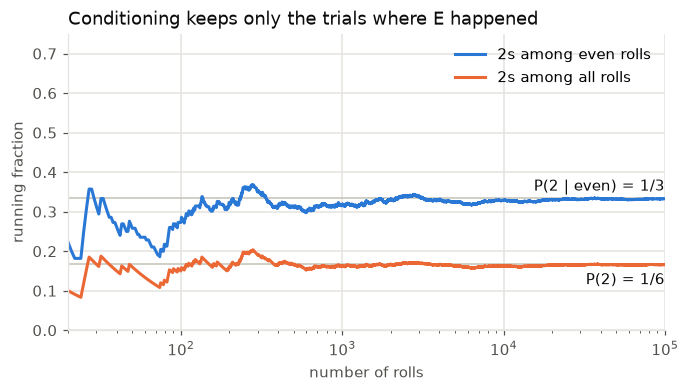

In [5]:
N_ROLLS = 100_000
sim = rng.integers(1, 7, size=N_ROLLS)
is_even, is_two = sim % 2 == 0, sim == 2
t = np.arange(1, N_ROLLS + 1)
cond_freq = np.cumsum(is_two) / np.maximum(np.cumsum(is_even), 1)   # 2s among the even rolls so far
plain_freq = np.cumsum(is_two) / t                                  # 2s among all rolls so far
print(f"after {N_ROLLS:,} rolls: P(2 | even) ~ {cond_freq[-1]:.4f} (exact 1/3),  "
      f"P(2) ~ {plain_freq[-1]:.4f} (exact 1/6)")

fig, ax = plt.subplots(figsize=(7, 3.5))
for level in (1 / 3, 1 / 6):
    ax.axhline(level, color=FAINT, lw=1)
ax.plot(t, cond_freq, color=BLUE, lw=2, label="2s among even rolls")
ax.plot(t, plain_freq, color=ORANGE, lw=2, label="2s among all rolls")
ax.text(N_ROLLS, 1 / 3 + 0.02, "P(2 | even) = 1/3", color=INK, ha="right")
ax.text(N_ROLLS, 1 / 6 - 0.05, "P(2) = 1/6", color=INK, ha="right")
ax.set(xscale="log", xlim=(20, N_ROLLS), ylim=(0, 0.75), xlabel="number of rolls", ylabel="running fraction")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Conditioning keeps only the trials where E happened", color=INK, loc="left")
plt.show()

## 4. The definition: restrict, then rescale (slide 17)

**From frequencies to a formula.** In $N$ trials, about $N \cdot P(E)$ land in $E$, and about $N \cdot P(E \cap F)$ land in both $E$ and $F$. So the fraction of $E$-trials in which $F$ also happens is about

$$\frac{N \cdot P(E \cap F)}{N \cdot P(E)} = \frac{P(E \cap F)}{P(E)}.$$

**Definition.** For events $E, F$ with $P(E) > 0$, the **conditional probability of $F$ given $E$** is

$$P(F \mid E) = \frac{P(E \cap F)}{P(E)}.$$

**Restricting the sample space.** The slide derives the same formula in steps. Write $X$ for the random outcome. Given $X \in E$, the outcome lies in $F$ exactly when it lies in $E \cap F$, so $P(X \in F \mid X \in E) = P(X \in E \cap F \mid X \in E)$, which is the share of $E$'s probability that sits inside $E \cap F$. Conditioning on $E$ does two things:

1. **Restrict.** Every outcome outside $E$ is now impossible, so its probability drops to 0. $E$ becomes the new sample space.
2. **Rescale.** Outcomes inside $E$ keep their *relative* sizes but are divided by $P(E)$, so that they add up to 1:
$$P(x \mid E) = \begin{cases} P(x)/P(E) & x \in E, \\ 0 & x \notin E. \end{cases}$$

Adding over $x \in F$ gives $P(F \mid E) = P(E \cap F)/P(E)$. In a Venn diagram, $E$ is now the whole world, and $P(F \mid E)$ is the fraction of $E$ that $F$ covers.

Since $P(\cdot \mid E)$ is itself a probability on the new sample space, every rule from Section 1 still holds after conditioning. For example, $P(F^c \mid E) = 1 - P(F \mid E)$.

**Equiprobable case.** If all outcomes of $\Omega$ are equally likely, the outcomes left in $E$ are still equally likely, so $P(F \mid E) = |E \cap F| / |E|$. That is the count used for the die: $|\lbrace 2 \rbrace| / |\lbrace 2, 4, 6 \rbrace| = 1/3$.

**Python check.** `condition` restricts a PMF to $E$ and rescales it. The result is a new PMF that adds to 1.

In [6]:
def condition(pmf, E):
    # Restrict to E (outcomes outside E get 0), then rescale by P(E) so the total is 1.
    PE = sum(pmf[x] for x in E)
    return {x: pmf[x] / PE if x in E else Fraction(0) for x in pmf}


def P_of(pmf, event):
    return sum(pmf[x] for x in event)


fair = {x: Fraction(1, 6) for x in range(1, 7)}
given_even = condition(fair, {2, 4, 6})
print("P(x | even):", {x: str(p) for x, p in given_even.items()})
show("total          ", sum(given_even.values()))
show("P(2 | even)    ", P_of(given_even, {2}))
show("P(E n F) / P(E)", P_of(fair, {2}) / P_of(fair, {2, 4, 6}))
show("P(not 2 | even)", P_of(given_even, {1, 3, 4, 5, 6}))

P(x | even): {1: '0', 2: '1/3', 3: '0', 4: '1/3', 5: '0', 6: '1/3'}
total          : 1 = 1.000000
P(2 | even)    : 1/3 = 0.333333
P(E n F) / P(E): 1/3 = 0.333333
P(not 2 | even): 2/3 = 0.666667


## 5. Example: a loaded 4-sided die (slide 18)

**Setup.** A loaded 4-sided die shows faces 1, 2, 3, 4 with probabilities 0.1, 0.2, 0.3, 0.4. Find $P(\text{roll} \ge 2 \mid \text{roll} \le 3)$.

**Step by step.**

1. Write the events as sets: "$\ge 2$" $= \lbrace 2, 3, 4 \rbrace$ and "$\le 3$" $= \lbrace 1, 2, 3 \rbrace$.
2. Intersect them: $\lbrace 2, 3, 4 \rbrace \cap \lbrace 1, 2, 3 \rbrace = \lbrace 2, 3 \rbrace$.
3. Apply the definition:
$$P(\ge 2 \mid \le 3) = \frac{P(\lbrace 2, 3 \rbrace)}{P(\lbrace 1, 2, 3 \rbrace)} = \frac{0.2 + 0.3}{0.1 + 0.2 + 0.3} = \frac{0.5}{0.6} = \frac{5}{6}.$$

**Restrict and rescale.** Learning "$\le 3$" removes face 4, and the remaining probabilities 0.1, 0.2, 0.3 are divided by their total 0.6, giving $1/6, 1/3, 1/2$. Then $P(\ge 2 \mid \le 3) = 1/3 + 1/2 = 5/6$.

This space is not equiprobable, so counting faces, $|\lbrace 2, 3 \rbrace| / |\lbrace 1, 2, 3 \rbrace| = 2/3$, gives the wrong answer. The definition weighs outcomes by probability; it does not count them.

**Python check.** Exact with the formula and with `condition`, then a simulation that keeps only the rolls that are at most 3.

In [7]:
die4 = {1: Fraction(1, 10), 2: Fraction(2, 10), 3: Fraction(3, 10), 4: Fraction(4, 10)}
at_least_2, at_most_3 = {2, 3, 4}, {1, 2, 3}

show("P(>=2 n <=3) / P(<=3)   ", P_of(die4, at_least_2 & at_most_3) / P_of(die4, at_most_3))
show("restrict and rescale    ", P_of(condition(die4, at_most_3), at_least_2))
show("wrong: count faces 2 / 3", Fraction(2, 3))

faces = rng.choice([1, 2, 3, 4], size=200_000, p=[0.1, 0.2, 0.3, 0.4])
kept = faces[faces <= 3]          # keep only the trials where "<= 3" happened
print(f"simulated {np.mean(kept >= 2):.4f}   exact {5 / 6:.4f}")

P(>=2 n <=3) / P(<=3)   : 5/6 = 0.833333
restrict and rescale    : 5/6 = 0.833333
wrong: count faces 2 / 3: 2/3 = 0.666667
simulated 0.8333   exact 0.8333


The bars show what conditioning does to the PMF. Face 4 disappears, and the other three bars grow by the same factor $1/0.6$, so their proportions $1 : 2 : 3$ are unchanged. The blue bars make up the event "$\ge 2$": before conditioning they hold $0.9$ of the probability, after conditioning $5/6$.

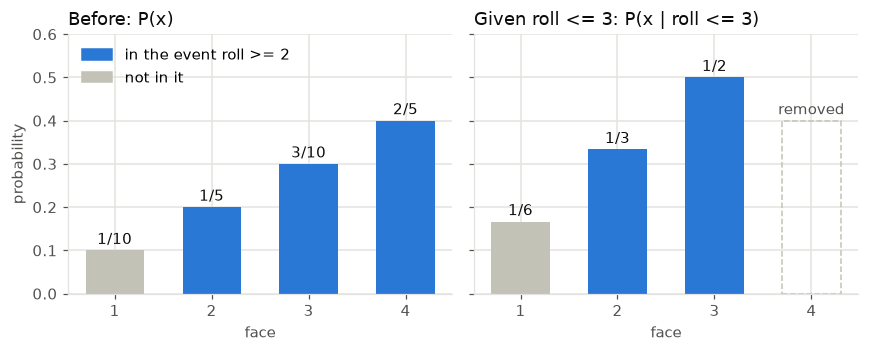

In [8]:
after = condition(die4, at_most_3)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), sharey=True)
for ax, pmf, title in [(axes[0], die4, "Before: P(x)"), (axes[1], after, "Given roll <= 3: P(x | roll <= 3)")]:
    for x, p in pmf.items():
        if p > 0:
            ax.bar(x, float(p), width=0.6, color=BLUE if x in at_least_2 else FAINT)
            ax.text(x, float(p) + 0.015, str(p), ha="center", color=INK)
        else:   # removed by conditioning: dashed outline at the old height
            ax.bar(x, float(die4[x]), width=0.6, fill=False, edgecolor=FAINT, linestyle="--")
            ax.text(x, float(die4[x]) + 0.015, "removed", ha="center", color=MUTED)
    ax.set(xticks=[1, 2, 3, 4], xlabel="face", ylim=(0, 0.6))
    ax.set_title(title, color=INK, loc="left")
axes[0].set_ylabel("probability")
handles = [Rectangle((0, 0), 1, 1, color=BLUE), Rectangle((0, 0), 1, 1, color=FAINT)]
axes[0].legend(handles, ["in the event roll >= 2", "not in it"], frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 6. The effect of conditioning: positive and negative correlation (slides 19-20)

**Intuition.** Learning that $E$ happened can push the probability of $F$ up, push it down, or leave it where it was. The three cases have names:

| Relation | Comparison | Meaning |
|---|---|---|
| Positive correlation | $P(F \mid E) > P(F)$ | $E$ makes $F$ more likely |
| Independence | $P(F \mid E) = P(F)$ | $E$ does not affect the probability of $F$ |
| Negative correlation | $P(F \mid E) < P(F)$ | $E$ makes $F$ less likely |

**Example (die).** Roll a fair die and let $F$ = "at least 5" $= \lbrace 5, 6 \rbrace$, so $P(F) = 1/3$. The slide leaves the conditioning event blank. Here are three choices that produce its three answers:

- $E = \lbrace 6 \rbrace$: $P(F \mid E) = 1 > 1/3$. Positive. Here $E \subseteq F$, so $E$ guarantees $F$.
- $E$ = "even" $= \lbrace 2, 4, 6 \rbrace$: $P(F \mid E) = |\lbrace 6 \rbrace| / 3 = 1/3 = P(F)$. Independent.
- $E$ = "at most 4" $= \lbrace 1, 2, 3, 4 \rbrace$: $P(F \mid E) = 0 < 1/3$. Negative. $E$ and $F$ are disjoint, so $E$ rules $F$ out.

The values 1 and 0 are the extremes, but any change counts. For example, $E$ = "at least 4" gives $P(F \mid E) = 2/3$, which is still a positive correlation.

(Session 4 defines the correlation of random variables. For the indicators of $E$ and $F$, its sign agrees with the classification here.)

**Python check.** The four events above, then a census of all 63 nonempty events $E \subseteq \lbrace 1, \dots, 6 \rbrace$. Independence needs an exact equality, so only a minority of events are independent of $F$.

In [9]:
def relation(p_cond, p):
    return "positive" if p_cond > p else "independent" if p_cond == p else "negative"


F = {5, 6}
for name, E in [("{6}", {6}), ("even", {2, 4, 6}), ("<= 4", {1, 2, 3, 4}), (">= 4", {4, 5, 6})]:
    p = Fraction(len(E & F), len(E))
    print(f"E = {name:5s} P(F | E) = {str(p):4s} vs P(F) = 1/3  ->  {relation(p, P_die(F))}")

counts = {"positive": 0, "independent": 0, "negative": 0}
for r in range(1, 7):
    for E in combinations(range(1, 7), r):
        counts[relation(Fraction(len(set(E) & F), r), P_die(F))] += 1
print("all 63 nonempty events E:", counts)

E = {6}   P(F | E) = 1    vs P(F) = 1/3  ->  positive
E = even  P(F | E) = 1/3  vs P(F) = 1/3  ->  independent
E = <= 4  P(F | E) = 0    vs P(F) = 1/3  ->  negative
E = >= 4  P(F | E) = 2/3  vs P(F) = 1/3  ->  positive
all 63 nonempty events E: {'positive': 25, 'independent': 13, 'negative': 25}


## 7. Independence: the informal definition (slide 21)

**Definition (informal).** Events $E$ and $F$ are **(statistically) independent**, written $E \perp\!\!\!\perp F$, if learning that $E$ happened does not change the probability of $F$:

$$P(F \mid E) = P(F).$$

**Visual meaning.** Both sides are fractions:

- $P(F) = P(F)/P(\Omega)$ is the share of the whole sample space covered by $F$;
- $P(F \mid E) = P(E \cap F)/P(E)$ is the share of $E$ covered by $F$.

Independence says that $F$ covers the same share of $E$ as of $\Omega$. If $F$ takes up a third of the world, it also takes up a third of $E$.

**Picture.** Let $\Omega$ be the unit square, with probability equal to area. In both panels below, $E$ is the left strip of width $3/5$ and $F$ has area $1/3$.

- Left: $F$ is the bottom strip of height $1/3$. It covers a third of $E$, the same share as of $\Omega$, so $E \perp\!\!\!\perp F$.
- Right: $F$ is squeezed inside $E$ (height $5/9$ over the width $3/5$, still area $1/3$). Now $F$ covers $5/9$ of $E$, more than its $1/3$ share of $\Omega$, so $E$ and $F$ are positively correlated.

left:  P(F | E): 1/3 = 0.333333
right: P(F)    : 1/3 = 0.333333
right: P(F | E): 5/9 = 0.555556


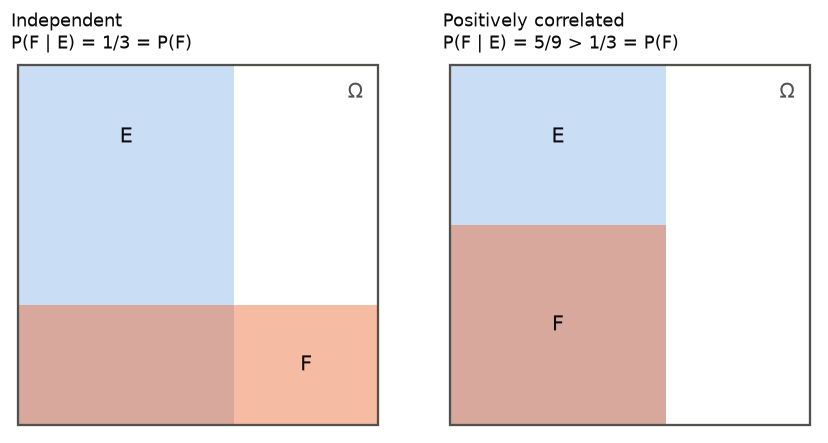

In [10]:
P_E, P_F = Fraction(3, 5), Fraction(1, 3)
P_EF_left = P_E * Fraction(1, 3)     # F = bottom strip of height 1/3
P_EF_right = P_E * Fraction(5, 9)    # F = bottom 5/9 of E only
show("left:  P(F | E)", P_EF_left / P_E)
show("right: P(F)    ", P_EF_right)          # F lies inside E, so P(F) = P(E n F)
show("right: P(F | E)", P_EF_right / P_E)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (fw, fh), F_xy, title in [
        (axes[0], (1, 1 / 3), (0.8, 1 / 6), "Independent\nP(F | E) = 1/3 = P(F)"),
        (axes[1], (0.6, 5 / 9), (0.3, 5 / 18), "Positively correlated\nP(F | E) = 5/9 > 1/3 = P(F)")]:
    ax.add_patch(Rectangle((0, 0), 0.6, 1, facecolor=BLUE, alpha=0.25, edgecolor="none"))
    ax.add_patch(Rectangle((0, 0), fw, fh, facecolor=ORANGE, alpha=0.45, edgecolor="none"))
    ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, edgecolor=MUTED, lw=1.5))
    ax.text(0.3, 0.8, "E", color=INK, ha="center", va="center", fontsize=14)
    ax.text(*F_xy, "F", color=INK, ha="center", va="center", fontsize=14)
    ax.text(0.96, 0.95, r"$\Omega$", color=MUTED, ha="right", va="top", fontsize=13)
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal")
    ax.set_axis_off()
    ax.set_title(title, color=INK, loc="left")
plt.tight_layout()
plt.show()

## 8. Unsurprising independence: two coin tosses (slide 22)

**Example.** Toss a fair coin twice. Let $H_1$ = "first toss heads" and $H_2$ = "second toss heads". The four outcomes HH, HT, TH, TT are equally likely, and $P(H_1) = P(H_2) = 1/2$. Given $H_1$, only HH and HT remain, and one of them has a second head:

$$P(H_2 \mid H_1) = \frac{|\lbrace \text{HH} \rbrace|}{|\lbrace \text{HH}, \text{HT} \rbrace|} = \frac{1}{2} = P(H_2).$$

So $H_1 \perp\!\!\!\perp H_2$: heads follows heads half the time, just as often as heads follows anything.

**Why it is unsurprising.** The two tosses are physically separate and the coin has no memory. Events about experiments that do not influence each other are always independent. In fact, that is how such experiments are modeled: giving each of the four outcomes probability $1/4 = 1/2 \cdot 1/2$ is exactly the statement that the tosses are independent.

The slide ends with the more interesting question: **can two events about the same single experiment be independent?** Section 9 answers it.

**Python check.** Exact by listing the four outcomes, and by simulation.

In [11]:
tosses = list(product("HT", repeat=2))     # HH, HT, TH, TT, equally likely


def P_toss(event, given=lambda w: True):
    kept = [w for w in tosses if given(w)]   # restrict the sample space
    return Fraction(sum(event(w) for w in kept), len(kept))


H1 = lambda w: w[0] == "H"
H2 = lambda w: w[1] == "H"
show("P(H2)     ", P_toss(H2))
show("P(H2 | H1)", P_toss(H2, given=H1))

flips = rng.integers(0, 2, size=(200_000, 2))   # 1 = heads
print(f"simulated P(H2 | H1) = {flips[flips[:, 0] == 1, 1].mean():.4f}")

P(H2)     : 1/2 = 0.500000
P(H2 | H1): 1/2 = 0.500000
simulated P(H2 | H1) = 0.4986


## 9. Three events on one die (slide 23)

**Setup.** Roll a fair die once and consider three events, all decided by the same roll:

| Event | Set | Probability |
|---|---|---|
| prime | $\lbrace 2, 3, 5 \rbrace$ | $1/2$ |
| odd | $\lbrace 1, 3, 5 \rbrace$ | $1/2$ |
| square | $\lbrace 1, 4 \rbrace$ | $1/3$ |

The sets overlap, so the events look intertwined. Check each pair by conditioning and counting:

1. $P(\text{odd} \mid \text{prime}) = \dfrac{|\lbrace 3, 5 \rbrace|}{|\lbrace 2, 3, 5 \rbrace|} = \dfrac{2}{3} > \dfrac{1}{2} = P(\text{odd})$. **Dependent**, positively: two of the three primes are odd.
2. $P(\text{prime} \mid \text{square}) = \dfrac{|\emptyset|}{|\lbrace 1, 4 \rbrace|} = 0 < \dfrac{1}{2} = P(\text{prime})$. **Dependent**, negatively: no square on a die is prime.
3. $P(\text{square} \mid \text{odd}) = \dfrac{|\lbrace 1 \rbrace|}{|\lbrace 1, 3, 5 \rbrace|} = \dfrac{1}{3} = P(\text{square})$. **Independent.**

So the answer to the slide's question is yes. "Square" and "odd" are decided by the same roll and even share the outcome 1, yet learning that the roll is odd leaves the chance of a square at exactly $1/3$. The squares take up a third of the odd faces, the same share as of all six faces. Independence is a statement about these proportions, not about physical separation.

**Python check.**

In [12]:
prime, odd, square = {2, 3, 5}, {1, 3, 5}, {1, 4}


def P_given(F, E):
    return Fraction(len(E & F), len(E))   # fair die: restrict to E and count


for f_name, F_, e_name, E in [("odd", odd, "prime", prime),
                              ("prime", prime, "square", square),
                              ("square", square, "odd", odd)]:
    pc = P_given(F_, E)
    print(f"P({f_name} | {e_name}) = {str(pc):4s} vs P({f_name}) = {str(P_die(F_)):4s} -> {relation(pc, P_die(F_))}")

P(odd | prime) = 2/3  vs P(odd) = 1/2  -> positive
P(prime | square) = 0    vs P(prime) = 1/2  -> negative
P(square | odd) = 1/3  vs P(square) = 1/3  -> independent


## 10. From the informal to the formal definition (slide 24)

The informal definition $P(F \mid E) = P(F)$ has two drawbacks:

1. **It is asymmetric.** It treats $E$ as the condition and $F$ as the target. Does $P(F \mid E) = P(F)$ also give $P(E \mid F) = P(E)$? It does, but that needs a proof.
2. **It is undefined when $P(E) = 0$**, because $P(F \mid E)$ divides by $P(E)$.

Multiply $P(F \mid E) = P(E \cap F)/P(E) = P(F)$ through by $P(E)$ to get a version with neither problem.

**Definition (formal).** Events $E$ and $F$ are **independent** if

$$P(E \cap F) = P(E) \cdot P(F),$$

and **dependent** otherwise. In words: the probability that both happen is the product of their probabilities.

**Properties.**

- **Symmetric** by inspection: swapping $E$ and $F$ changes nothing.
- **Defined when $P(E) = 0$.** Then $P(E \cap F) \le P(E) = 0 = P(E)P(F)$, so an event of probability 0 is independent of every event.
- **Agrees with the informal version** when $P(E) > 0$: divide both sides by $P(E)$. This also proves the symmetry of the informal version. If $P(E), P(F) > 0$ and $P(F \mid E) = P(F)$, then $P(E \cap F) = P(E)P(F)$, so $P(E \mid F) = P(E \cap F)/P(F) = P(E)$.
- **Correlation is symmetric too.** The same algebra gives $P(F \mid E) > P(F) \iff P(E \cap F) > P(E)P(F) \iff P(E \mid F) > P(E)$. "$E$ makes $F$ more likely" holds exactly when "$F$ makes $E$ more likely". For example, $P(\text{prime} \mid \text{odd}) = 2/3 > 1/2$ as well.
- **Complements.** If $E \perp\!\!\!\perp F$, then $E \perp\!\!\!\perp F^c$:
$$P(E \cap F^c) = P(E) - P(E \cap F) = P(E) - P(E)P(F) = P(E)\big(1 - P(F)\big) = P(E)\,P(F^c).$$
Applying this twice gives $E^c \perp\!\!\!\perp F^c$. On the die, "square" is independent of "even" as well as "odd".
- **Disjoint is not independent.** If $E \cap F = \emptyset$ and both have positive probability, then $P(E \cap F) = 0 < P(E)P(F)$. Disjoint events are strongly *negatively* correlated, because each one rules the other out. Prime and square are an example.

**Python check.** Test the product form directly, and confirm on all $63^2$ pairs of nonempty die events that the sign of the correlation does not depend on which event is the condition.

In [13]:
def independent(E, F):
    return P_die(E & F) == P_die(E) * P_die(F)


print("square, odd  :", independent(square, odd))
print("odd, square  :", independent(odd, square))
print("prime, square:", independent(prime, square), " (disjoint, both with positive probability)")
print("empty, prime :", independent(set(), prime), "  (probability-0 events are independent of everything)")
print("square, even :", independent(square, omega - odd), "  (complement of an independent event)")

events = [set(c) for r in range(1, 7) for c in combinations(range(1, 7), r)]
print(f"correlation sign symmetric on all {len(events) ** 2} pairs:",
      all(relation(P_given(F_, E), P_die(F_)) == relation(P_given(E, F_), P_die(E)) for E in events for F_ in events))

square, odd  : True
odd, square  : True
prime, square: False  (disjoint, both with positive probability)
empty, prime : True   (probability-0 events are independent of everything)
square, even : True   (complement of an independent event)
correlation sign symmetric on all 3969 pairs: True


## 11. Three events: pairwise vs mutual independence (builds on slides 23-24)

With three events, "independent" can mean two different things.

**Definition.** Events $A, B, C$ are **pairwise independent** if every pair is independent:

$$P(A \cap B) = P(A)P(B), \qquad P(A \cap C) = P(A)P(C), \qquad P(B \cap C) = P(B)P(C).$$

They are **mutually independent** (or simply *independent*) if, in addition,

$$P(A \cap B \cap C) = P(A)\,P(B)\,P(C).$$

Mutual independence means that no information about some of the events, alone or combined, changes the probability of another one; for example, $P(C \mid A \cap B) = P(C)$. Pairwise independence only promises this when you learn about one event at a time. For $n$ events, mutual independence requires the product rule for every subcollection of two or more events: $2^n - n - 1$ equations in all, which is 4 when $n = 3$.

**Back to the slide's die.** Prime, odd, and square are not even pairwise independent: only the pair (square, odd) is. In fact, one roll of a fair die cannot carry three pairwise independent events unless one of them has probability 0 or 1. Every probability on a fair die is a multiple of $1/6$. Writing $P(A) = a/6$ and $P(B) = b/6$ with $1 \le a, b \le 5$, independence needs $ab/36$ to be a multiple of $1/6$, that is, $6 \mid ab$. This happens only when one of $a, b$ is 3 and the other is 2 or 4. So every independent pair contains exactly one event of probability $1/2$. Among three events, that is impossible: if two of them have probability $1/2$, that pair fails, and if at most one does, the other two form a failing pair. The brute-force check below confirms it.

**Two dice: pairwise but not mutually independent.** Roll two fair dice and let

- $A$ = "the first die is odd",
- $B$ = "the second die is odd",
- $C$ = "the sum is even".

Each event has probability $1/2$. $A$ and $B$ concern separate dice, so $P(A \cap B) = 1/4$. Next, $A \cap C$ = "first die odd and sum even" = "both dice odd", so $P(A \cap C) = 1/4 = P(A)P(C)$, and $B \cap C$ works the same way. The three events are pairwise independent. But if both dice are odd, the sum is certainly even: $A \cap B \subseteq C$, so

$$P(A \cap B \cap C) = P(A \cap B) = \frac{1}{4} \ne \frac{1}{8} = P(A)P(B)P(C).$$

They are not mutually independent. In conditional terms: $P(C \mid A) = P(C \mid B) = 1/2$, but $P(C \mid A \cap B) = 1$. Either event alone says nothing about $C$; together they settle it.

**The triple product alone is not enough either.** On two dice, let $A'$ = "first die in $\lbrace 1, 2, 3 \rbrace$", $B'$ = "first die in $\lbrace 3, 4, 5 \rbrace$", $C'$ = "sum is 9". Then $P(A') = P(B') = 1/2$ and $P(C') = 4/36 = 1/9$. The only outcome in all three is $(3, 6)$, so $P(A' \cap B' \cap C') = 1/36 = P(A')P(B')P(C')$. Yet $A' \cap B'$ = "first die is 3" has probability $1/6 \ne 1/4$. That is why the definition demands all four equations.

**Python check.**

In [14]:
# 1) One fair die: no three events with 0 < P < 1 are pairwise independent.
nontrivial = [frozenset(c) for r in range(1, 6) for c in combinations(range(1, 7), r)]
triples = [(a, b, c) for a, b, c in combinations(nontrivial, 3)
           if independent(a, b) and independent(a, c) and independent(b, c)]
print(f"{len(nontrivial)} nontrivial events on one die, pairwise independent triples: {len(triples)}")

62 nontrivial events on one die, pairwise independent triples: 0

In [15]:
dice = list(product(range(1, 7), repeat=2))   # 36 equally likely ordered pairs


def P2(*events):
    # Probability that all the given events happen, on two fair dice.
    return Fraction(sum(all(ev(w) for ev in events) for w in dice), len(dice))


# 2) Pairwise but not mutually independent.
A = lambda w: w[0] % 2 == 1            # first die odd
B = lambda w: w[1] % 2 == 1            # second die odd
C = lambda w: (w[0] + w[1]) % 2 == 0   # sum even
for name, (X, Y) in {"A, B": (A, B), "A, C": (A, C), "B, C": (B, C)}.items():
    print(f"{name}: P(both) = {P2(X, Y)}   product = {P2(X) * P2(Y)}")
print(f"A, B, C: P(all three) = {P2(A, B, C)}   product = {P2(A) * P2(B) * P2(C)}")
show("P(C | A n B)", P2(A, B, C) / P2(A, B))

# 3) Triple product holds, but a pair is dependent.
A3 = lambda w: w[0] in (1, 2, 3)
B3 = lambda w: w[0] in (3, 4, 5)
C3 = lambda w: w[0] + w[1] == 9
print(f"P(A' n B' n C') = {P2(A3, B3, C3)}   product = {P2(A3) * P2(B3) * P2(C3)}")
print(f"P(A' n B')      = {P2(A3, B3)}    product = {P2(A3) * P2(B3)}")

A, B: P(both) = 1/4   product = 1/4
A, C: P(both) = 1/4   product = 1/4
B, C: P(both) = 1/4   product = 1/4
A, B, C: P(all three) = 1/4   product = 1/8
P(C | A n B): 1 = 1.000000
P(A' n B' n C') = 1/36   product = 1/36
P(A' n B')      = 1/6    product = 1/4
